# 06 — Relaciones y VIF de clasificación (BD_IPSA_1940), solo sobre train

> **Split definitivo, no exploratorio.** Este notebook usa `split_clasificacion()` (`src/datos.py`):
> 80/20 por **hacienda (FAZ)**, `StratifiedGroupKFold(5, shuffle=True, random_state=42)` estratificado por la clase
> combinada TCH × sacarosa, con el fold 0 como test. *(Agrupar por lote
> FAZ + TAL dejaba lotes hermanos de la misma hacienda y período a ambos lados del corte.)* **Es el mismo split que se usará en el bloque formal de Pipeline y
> modelado.** Se adelantó para que los estadísticos que deciden la selección de variables (correlaciones, información
> mutua, VIF) se calculen **solo con train**, igual que el VIF de regresión (notebook 03, sobre el train del notebook
> 02). **Si en ese bloque se ajusta el split** (otro `random_state` u otro criterio de grupo), **hay que volver a
> correr este notebook**, porque cambiarían las filas que ve el cálculo.

**Objetivo:** con el criterio de las reglas de referencia del curso (RN) para variables con correlación baja, decidir qué predictoras aportan información a
cada target (Bajo/Medio/Alto de TCH y de sacarosa) y medir la multicolinealidad (VIF). El test no se toca.

> **Alcance:** solo CC01-1940 madurada con BONUS 250 EC y cosechada a máquina.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr
from sklearn.metrics import mutual_info_score

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src.datos import (CLASES, PREDICTORAS_CLASIFICACION, TARGETS_CLASIFICACION, cargar_ipsa, categorizar,
                       clase_combinada, grupos_hacienda_ipsa, grupos_ipsa, split_clasificacion)
from src.evaluacion import COLORES, vif

FIG_DIR = RAIZ / "reports" / "figures"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## 1. Verificación del split

In [2]:
ipsa = cargar_ipsa()
train, test = split_clasificacion(ipsa)
g_tr, g_te = set(grupos_hacienda_ipsa(train)), set(grupos_hacienda_ipsa(test))
print(f"Train: {len(train):,} filas, {len(g_tr):,} haciendas | Test: {len(test):,} filas, {len(g_te):,} haciendas | "
      f"% test: {len(test) / len(ipsa):.1%}")
assert not g_tr & g_te, "hay haciendas en train y en test"
assert not set(grupos_ipsa(train)) & set(grupos_ipsa(test))
assert 0.19 <= len(test) / len(ipsa) <= 0.21

filas = []
for t in TARGETS_CLASIFICACION:
    c_tr, c_te = categorizar(train[t], t), categorizar(test[t], t)
    tabla = pd.crosstab(pd.concat([c_tr, c_te]), ["train"] * len(c_tr) + ["test"] * len(c_te))
    p = chi2_contingency(tabla)[1]
    for nombre, c in (("train", c_tr), ("test", c_te)):
        filas.append({"target": t, "partición": nombre, **(c.value_counts(normalize=True).reindex(CLASES) * 100).round(1),
                      "χ² p (train vs test)": round(p, 3)})
reparto = pd.DataFrame(filas).set_index(["target", "partición"])
display(reparto)
assert (reparto["χ² p (train vs test)"] > 0.5).all()

Train: 1,749 filas, 229 haciendas | Test: 438 filas, 56 haciendas | % test: 20.0%


Bajo  Medio  Alto  χ² p (train vs test)
target   partición                                         
TCH      train      22.7   38.9  38.4                 0.986
         test       23.1   38.8  38.1                 0.986
sacarosa train      21.6   36.7  41.7                 0.995
         test       21.5   36.5  42.0                 0.995

**Conclusión 1.** Ninguna hacienda (y por lo tanto ningún lote) está a la vez en train y en test, el test es el
20 % y el reparto de clases es casi idéntico en las dos particiones para los dos targets (ver `src/datos.py::split_clasificacion`; "Split —
Clasificación").

## 2. Preparación de train (temporal)

Se aplican **sobre train** las reglas aprobadas que cambian valores, para que las relaciones no las distorsionen.
Es una derivación ad hoc y temporal, hasta que el transformador de reglas de negocio de clasificación lo formalice en
el bloque de Pipeline:
- `anio` = `periodo // 100`; `mes_cosecha` = `mes` como categórica. Las crudas `mes` y `periodo` no se
  usan en ningún cálculo.
- `dosismad` = 0 o > 3 → NaN; `semsmad` < 0 → NaN (imputación y outliers aprobados).
- `lluvias` = 0 → NaN + `tiene_dato_lluvia`. El recorte de 300 mm/mes × (edad − 10) no afecta ninguna fila.

No se imputa nada en §3: cada relación usa las filas con dato de esa variable. El VIF (§5) sí necesita una matriz
completa, y ahí se imputa con la estrategia aprobada, con estadísticos de train.

In [3]:
def preparar(df):
    """TEMPORAL: reglas aprobadas aplicadas ad hoc, hasta el transformador del Pipeline (bloque de split y Pipeline)."""
    d = df.copy()
    d["anio"] = d["periodo"] // 100
    d["mes_cosecha"] = d["mes"].astype("category")
    d.loc[d["dosismad"].eq(0) | d["dosismad"].gt(3), "dosismad"] = np.nan
    d.loc[d["semsmad"] < 0, "semsmad"] = np.nan
    d["tiene_dato_lluvia"] = (d["lluvias"] > 0).astype(int)
    d["lluvias"] = d["lluvias"].where(d["lluvias"] > 0)
    ventana = d["edad"] - 10
    tope = (300 * ventana).where(ventana >= 1)
    d["lluvias"] = d["lluvias"].clip(upper=tope)  # NaN en tope = sin recorte
    return d.drop(columns=["mes", "periodo"])

tr = preparar(train)
print("NaN tras las reglas (train):", tr[["dosismad", "semsmad", "lluvias"]].isna().sum().to_dict())
assert set(PREDICTORAS_CLASIFICACION) - {"mes", "periodo"} <= set(tr.columns)

NUMERICAS = ["edad", "cortes", "semsmad", "dosismad", "lluvias", "anio"]
CATEGORICAS = ["grupo_tenencia", "mes_cosecha", "tiene_dato_lluvia"]

NaN tras las reglas (train): {'dosismad': 1, 'semsmad': 2, 'lluvias': 549}


## 3. Relevancia de cada predictora para cada target

RN propone tres chequeos y descartar una variable solo si es poco informativa en **al menos 2 de los 3**:

1. **Target por bins de la variable:** reparto de clases por quintiles de train (numéricas continuas), por nivel
   (`cortes`, con 6+ agrupado) o por categoría,
   con un test χ². Detecta relaciones no monótonas.
2. **Información mutua frente a correlación lineal:** `mutual_info_score` sobre la variable discretizada en
   quintiles, con un **test de permutación** (500 permutaciones de la clase), comparada con el ρ de Spearman frente al
   target continuo. MI significativa con ρ ≈ 0 indica una relación no lineal.
3. **Importancia en un modelo de árboles:** **no disponible**. El proyecto no usa árboles (fuera del curso; trabajo
   futuro). Con dos chequeos, "≥ 2 de 3" significa que la variable tiene que ser poco informativa
   **en los dos**.

*Por qué MI sobre quintiles y no el estimador continuo (kNN) de `mutual_info_classif`:* `semsmad` y `dosismad`
vienen con un decimal y `dosismad` tiene ~17 valores distintos. Con tantos empates, el estimador kNN devolvía MI = 0
en variables que el χ² marca con p < 1e-8 (exploración previa). Discretizar elimina ese sesgo y deja el MI
comparable con el de las categóricas.

**Cautelas:** (a) hay varios registros por hacienda (mediana 4, máx. 101), así que las filas no son independientes
y los p-valores son algo optimistas. (b) Son ~9 pruebas por target: un p entre 0.01 y 0.05 es una señal débil (con Bonferroni el corte sería
≈ 0.006).

In [4]:
rng = np.random.default_rng(42)

DISCRETAS = {"cortes": 6}  # se agrupa por nivel (6 = 6 o más): los quintiles por rango partirían cortes = 2 en dos bins

def discretizar(x):
    if x.name in DISCRETAS:
        return x.clip(upper=DISCRETAS[x.name])
    return pd.qcut(x.rank(method="first"), 5, labels=False) if x.nunique() > 12 else x

def mi_permutacion(xb, y, B=500):
    obs = mutual_info_score(xb, y)
    nulo = np.array([mutual_info_score(xb, rng.permutation(y)) for _ in range(B)])
    return obs, (1 + (nulo >= obs).sum()) / (B + 1)

filas = []
for t in TARGETS_CLASIFICACION:
    y_clase = categorizar(tr[t], t).astype(str)
    for v in NUMERICAS + CATEGORICAS:
        m = tr[v].notna()
        xb = discretizar(tr.loc[m, v]) if v in NUMERICAS else tr.loc[m, v].astype(str)
        yc = y_clase[m].to_numpy()
        p_bins = chi2_contingency(pd.crosstab(xb, yc))[1]
        mi, p_mi = mi_permutacion(xb, yc)
        rho = spearmanr(tr.loc[m, v], tr.loc[m, t]).statistic if v in NUMERICAS else np.nan
        filas.append({"target": t, "variable": v, "n": int(m.sum()), "ρ Spearman": rho, "χ² bins p": p_bins,
                      "MI (quintiles)": mi, "MI perm p": p_mi})
relev = pd.DataFrame(filas).set_index(["target", "variable"])
relev["poco informativa en"] = (relev["χ² bins p"] >= 0.05).astype(int) + (relev["MI perm p"] >= 0.05).astype(int)
relev["regla RN (2 de 2)"] = np.where(relev["poco informativa en"] == 2, "candidata a descarte", "conservar")
display(relev.round({"ρ Spearman": 3, "χ² bins p": 4, "MI (quintiles)": 4, "MI perm p": 3}))

n  ρ Spearman  χ² bins p  MI (quintiles)  MI perm p  poco informativa en     regla RN (2 de 2)
target   variable                                                                                                            
TCH      edad               1749       0.188     0.0000          0.0187      0.002                    0             conservar
         cortes             1749      -0.312     0.0000          0.0478      0.002                    0             conservar
         semsmad            1747       0.005     0.0948          0.0039      0.082                    2  candidata a descarte
         dosismad           1748       0.038     0.2072          0.0031      0.214                    2  candidata a descarte
         lluvias            1200       0.154     0.0004          0.0118      0.002                    0             conservar
         anio               1749      -0.216     0.0000          0.0370      0.002                    0             conservar
         grupo_tenencia     1749         NaN     0.0000          0.0140      0.002                    0             conservar
         mes_cosecha        1749         NaN     0.6465          0.0054      0.657                    2  candidata a descarte
         tiene_dato_lluvia  1749         NaN     0.0093          0.0027      0.004                    0             conservar
sacarosa edad               1749       0.025     0.0000          0.0120      0.002                    0             conservar
         cortes             1749       0.073     0.0911          0.0047      0.090                    2  candidata a descarte
         semsmad            1747       0.196     0.0000          0.0227      0.002                    0             conservar
         dosismad           1748      -0.056     0.0184          0.0054      0.014                    0             conservar
         lluvias            1200      -0.285     0.0000          0.0484      0.002                    0             conservar
         anio               1749       0.114     0.0000          0.0348      0.002                    0             conservar
         grupo_tenencia     1749         NaN     0.5828          0.0008      0.591                    2  candidata a descarte
         mes_cosecha        1749         NaN     0.0000          0.1175      0.002                    0             conservar
         tiene_dato_lluvia  1749         NaN     0.1908          0.0010      0.200                    2  candidata a descarte

### 3.1 Forma de la relación (dónde importa la no linealidad)

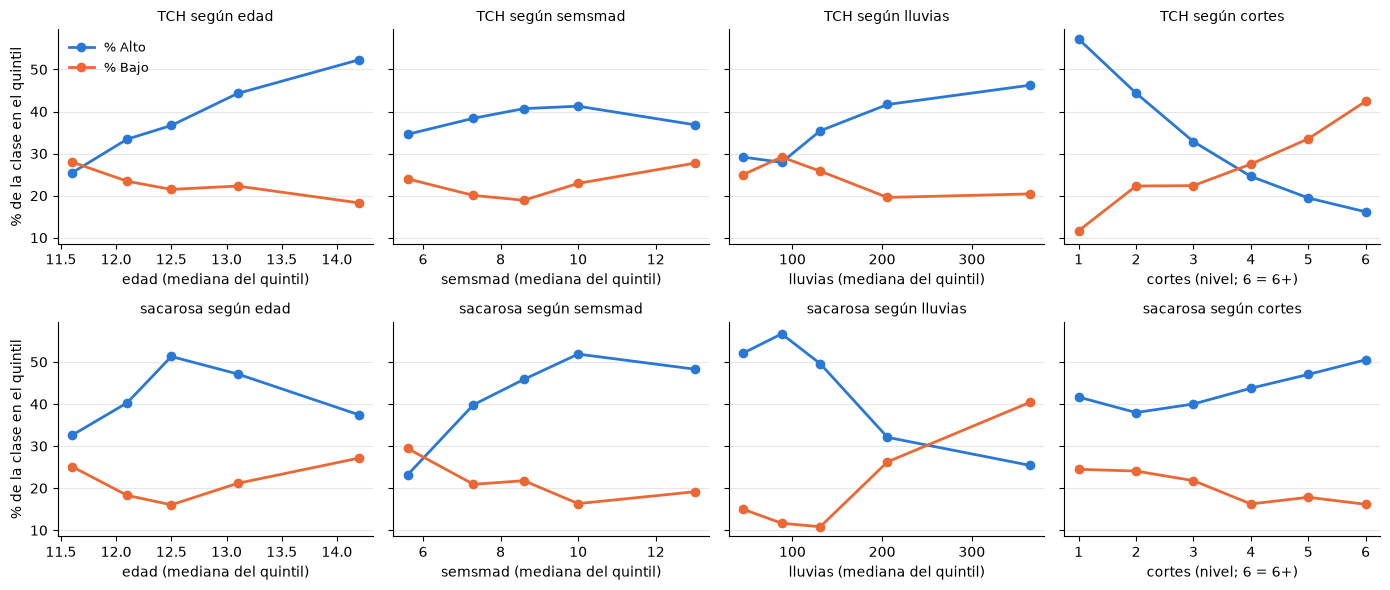

In [5]:
VARS_FORMA = ["edad", "semsmad", "lluvias", "cortes"]
fig, axes = plt.subplots(2, len(VARS_FORMA), figsize=(14, 6), sharey=True)
for i, t in enumerate(TARGETS_CLASIFICACION):
    y_clase = categorizar(tr[t], t).astype(str)
    for j, v in enumerate(VARS_FORMA):
        ax = axes[i, j]
        m = tr[v].notna()
        q = discretizar(tr.loc[m, v])
        pct = pd.crosstab(q, y_clase[m], normalize="index") * 100
        centro = tr.loc[m, v].groupby(q).median()
        ax.plot(centro, pct["Alto"], marker="o", lw=2, ms=6, color=COLORES["serie1"], label="% Alto")
        ax.plot(centro, pct["Bajo"], marker="o", lw=2, ms=6, color=COLORES["serie2"], label="% Bajo")
        ax.set_title(f"{t} según {v}", fontsize=10)
        ax.set_xlabel(f"{v} (nivel; 6 = 6+)" if v in DISCRETAS else f"{v} (mediana del quintil)")
        if j == 0:
            ax.set_ylabel("% de la clase en el quintil")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.3)
axes[0, 0].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_clf_relaciones_quintiles.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
y_sac = categorizar(tr["sacarosa"], "sacarosa").astype(str)
por_mes = pd.crosstab(tr["mes_cosecha"], y_sac, normalize="index").mul(100).round(0)[["Bajo", "Medio", "Alto"]]
por_mes["n"] = tr["mes_cosecha"].value_counts().sort_index()
por_mes["lluvias mediana"] = tr.groupby("mes_cosecha", observed=True)["lluvias"].median()
display(por_mes.T)
print(f"ρ Spearman entre lluvias y % Alto de sacarosa por mes: "
      f"{spearmanr(por_mes['lluvias mediana'], por_mes['Alto']).statistic:.2f}")

mes_cosecha,1,2,3,4,5,6,7,8,9,10,11,12
sacarosa,,,,,,,,,,,,
Bajo,20.0,15.0,7.0,31.0,36.0,51.0,31.0,12.0,8.0,2.0,12.0,28.0
Medio,36.0,44.0,31.0,47.0,47.0,36.0,49.0,41.0,26.0,25.0,34.0,40.0
Alto,44.0,40.0,62.0,22.0,17.0,13.0,20.0,46.0,66.0,73.0,53.0,33.0
n,179.0,52.0,152.0,147.0,159.0,189.0,102.0,99.0,175.0,206.0,122.0,167.0
lluvias mediana,134.0,117.0,102.0,177.0,207.0,176.5,130.0,131.0,74.5,117.5,136.0,206.0


ρ Spearman entre lluvias y % Alto de sacarosa por mes: -0.69


## 4. Exploratorio: `lluvias` frente a su tasa por mes

`lluvias` suma la lluvia de una ventana que **crece con la edad** (del mes 10 al corte, 05 §6). Parte de su relación
con los targets podría ser una relación con la edad. Se compara con la tasa `lluvias / (edad − 10)` en ventanas de
≥ 1 mes. **No es una predictora aprobada:** solo se mide.

In [7]:
tasa = tr["lluvias"] / (tr["edad"] - 10).where(tr["edad"] - 10 >= 1)
print(f"ρ con edad: lluvias {spearmanr(tr['lluvias'], tr['edad'], nan_policy='omit').statistic:.2f} | "
      f"tasa {spearmanr(tasa, tr['edad'], nan_policy='omit').statistic:.2f}")
for t in TARGETS_CLASIFICACION:
    y_clase = categorizar(tr[t], t).astype(str)
    m = tasa.notna()
    mi, p = mi_permutacion(discretizar(tasa[m]), y_clase[m].to_numpy())
    print(f"{t}: ρ tasa {spearmanr(tasa[m], tr.loc[m, t]).statistic:+.3f} (lluvias {relev.loc[(t, 'lluvias'), 'ρ Spearman']:+.3f}) | "
          f"MI tasa {mi:.4f} p={p:.3f} (lluvias {relev.loc[(t, 'lluvias'), 'MI (quintiles)']:.4f})")

ρ con edad: lluvias 0.55 | tasa 0.13


TCH: ρ tasa +0.075 (lluvias +0.154) | MI tasa 0.0042 p=0.257 (lluvias 0.0118)


sacarosa: ρ tasa -0.369 (lluvias -0.285) | MI tasa 0.0635 p=0.002 (lluvias 0.0484)


## 5. Correlación entre predictoras y VIF (diseño de la logística, train)

Para el VIF hace falta una matriz completa. Se imputa con la estrategia **aprobada**, usando estadísticos de
**train**: `lluvias` con la mediana por `grupo_tenencia` × `mes_cosecha` (fallback `mes_cosecha`), y después
`log1p`. `dosismad` y `semsmad` con la mediana de train. Las categóricas van como dummies con `drop_first`, como en
el diseño lineal de regresión.

In [8]:
display(tr[NUMERICAS].corr(method="spearman").round(2))

z = tr.copy()
med_gm = z.groupby(["grupo_tenencia", "mes_cosecha"], observed=True)["lluvias"].median()
med_m = z.groupby("mes_cosecha", observed=True)["lluvias"].median()
falta = z["lluvias"].isna()
z.loc[falta, "lluvias"] = [med_gm.get((g, m), np.nan) for g, m in zip(z.loc[falta, "grupo_tenencia"], z.loc[falta, "mes_cosecha"])]
z["lluvias"] = z["lluvias"].fillna(z["mes_cosecha"].map(med_m).astype(float))
for v in ("dosismad", "semsmad"):
    z[v] = z[v].fillna(z[v].median())
assert z[NUMERICAS].notna().all().all()

Z = pd.concat([
    z[["edad", "cortes", "semsmad", "dosismad", "anio", "tiene_dato_lluvia"]],
    np.log1p(z["lluvias"]).rename("log1p_lluvias"),
    pd.get_dummies(z["grupo_tenencia"].astype(str), prefix="gt", drop_first=True),
    pd.get_dummies(z["mes_cosecha"].astype(str), prefix="mes", drop_first=True),
], axis=1)
tabla_vif = vif(Z).round(2)
display(tabla_vif.to_frame().T)
assert tabla_vif.max() < 5

,edad,cortes,semsmad,dosismad,lluvias,anio
edad,1.00,-0.38,0.62,0.07,0.55,-0.23
cortes,-0.38,1.00,-0.03,-0.07,-0.22,0.31
semsmad,0.62,-0.03,1.00,0.07,0.32,-0.07
dosismad,0.07,-0.07,0.07,1.00,0.25,-0.45
lluvias,0.55,-0.22,0.32,0.25,1.00,-0.39
anio,-0.23,0.31,-0.07,-0.45,-0.39,1.00


,gt_3,gt_2,edad,semsmad,mes_10,mes_9,mes_6,mes_5,mes_12,mes_4,log1p_lluvias,mes_3,mes_11,mes_7,dosismad,tiene_dato_lluvia,mes_8,anio,mes_2,cortes
VIF,3.49,2.51,2.48,2.22,2.08,1.97,1.96,1.92,1.89,1.82,1.77,1.76,1.64,1.57,1.55,1.54,1.53,1.51,1.29,1.27


## 6. Conclusiones (split por hacienda)

**Multicolinealidad: no hay problema.** Todos los VIF son < 5 (máximo 3.49, `grupo_tenencia` 3; en las numéricas el
máximo es `edad`, 2.48). Las correlaciones más altas entre predictoras son `edad`–`semsmad` (ρ 0.62, cosechas
postergadas), `edad`–`lluvias` (0.55, ventana que crece con la edad, §4) y `dosismad`–`anio` (−0.45). Ninguna obliga a
eliminar variables, y los coeficientes de la logística se pueden interpretar.

**Relevancia (tabla §3):**

| Variable | TCH | Sacarosa |
|---|---|---|
| `edad` | Sí (ρ 0.19): más edad, más "Alto" | Sí, **no lineal** (ρ 0.03; bins y MI significativos) |
| `cortes` | Sí, la más fuerte entre las agronómicas (ρ −0.31) | **Candidata a descarte** (p 0.09 / 0.09) |
| `semsmad` | **Candidata a descarte** (p 0.09 / 0.08; todo IPSA está madurado) | Sí (ρ 0.20): % Alto sube y se estabiliza |
| `dosismad` | **Candidata a descarte** (p 0.21 / 0.21) | Débil (p 0.02 / 0.01) |
| `lluvias` | Sí (p 0.0004; ρ 0.15) | Sí, **fuerte** (ρ −0.29) |
| indicador de lluvia (`tiene_dato_lluvia` aquí = 1 con dato; en el Pipeline `falta_dato_lluvia`) | Sí (p 0.009 / 0.004) | **Candidata a descarte** (p 0.19 / 0.20) |
| `anio` | Sí (ρ −0.22) | Sí (ρ 0.11) |
| `grupo_tenencia` | Sí (p < 1e-4) | **Candidata a descarte** (p 0.58 / 0.59) |
| `mes_cosecha` | **Candidata a descarte** (p 0.65 / 0.66) | **La más fuerte** (MI 0.118): % Alto de 62–73 % en marzo, septiembre y octubre frente a 13–22 % en abril–julio; ρ −0.69 con la lluvia del mes |

**Cambios respecto del split por lote:** se agregan como candidatas `dosismad` (TCH) y el indicador de lluvia
(sacarosa), y `lluvias` deja de estar en el límite para TCH. Las demás candidatas se mantienen.

**Lectura:** TCH depende del ciclo del lote (`cortes`, `edad`, `anio`, tenencia, lluvia del tramo final). La
sacarosa depende de la **época de cosecha** (`mes_cosecha`, `lluvias`) y del madurante (`semsmad`), en línea con la literatura
de maduración química.

**Hallazgo exploratorio (§4):** la tasa `lluvias / (edad − 10)` se desacopla de la edad (ρ 0.13 frente a 0.55) y es
más informativa para sacarosa que la suma (MI 0.064 frente a 0.048; ρ −0.37 frente a −0.29). Para TCH no aporta
(p 0.26). Se mantiene como sensibilidad, porque depende de una ventana de lluvia inferida y no confirmada.

## 7. `edad` frente a sacarosa: forma, confusión y especificación en la logística

§3 mostró que la relación es no lineal (ρ ≈ 0, pero bins y MI significativos). Aquí se ubica el punto de inflexión,
se mide el soporte de cada tramo, se comprueba si la curvatura sobrevive al controlar por `semsmad` y `mes_cosecha`,
y se comparan especificaciones con CV en train. **Es evidencia exploratoria:** `lluvias` se imputa con la mediana
simple y la regularización no se ajusta. No es el Pipeline aprobado.

In [9]:
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess

y_sac = categorizar(tr["sacarosa"], "sacarosa").astype(str)
tramos = pd.cut(tr["edad"], [10, 11.5, 12, 12.5, 13, 13.5, 14, 15, 16, 22], right=False)
soporte = pd.crosstab(tramos, y_sac, normalize="index").mul(100).round(1)[["Bajo", "Alto"]]
soporte["n train"] = tramos.value_counts().sort_index()
display(soporte)
lw = lowess((y_sac == "Alto").astype(float), tr["edad"], frac=0.3)
print(f"Máximo LOWESS de % Alto en edad = {lw[lw[:, 1].argmax(), 0]:.1f} meses | filas ≥ 15: {(tr['edad'] >= 15).sum()}, ≥ 16: {(tr['edad'] >= 16).sum()}")

d = tr.dropna(subset=["semsmad"])
X = pd.get_dummies(d["mes_cosecha"].astype(str), prefix="mes", drop_first=True).astype(float)
X = X.assign(semsmad=d["semsmad"], semsmad2=d["semsmad"] ** 2, cortes=d["cortes"], anio=d["anio"],
             edad=d["edad"] - 12.8, edad2=(d["edad"] - 12.8) ** 2)
logit = sm.Logit((y_sac[d.index] == "Alto").astype(int), sm.add_constant(X)).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(grupos_hacienda_ipsa(train).loc[d.index])[0]})
print(f"Alto frente al resto, controlando semsmad (+²), mes_cosecha, cortes y anio: edad² = {logit.params['edad2']:.4f}, "
      f"p (cluster por hacienda) = {logit.pvalues['edad2']:.3f}")

sacarosa,Bajo,Alto,n train
edad,,,
"[10.0, 11.5)",32.7,24.8,101
"[11.5, 12.0)",21.4,34.5,313
"[12.0, 12.5)",17.1,45.9,392
"[12.5, 13.0)",18.6,48.3,354
"[13.0, 13.5)",20.5,49.3,219
"[13.5, 14.0)",24.1,43.8,137
"[14.0, 15.0)",21.6,36.6,153
"[15.0, 16.0)",27.3,34.1,44
"[16.0, 22.0)",58.3,19.4,36


Máximo LOWESS de % Alto en edad = 12.6 meses | filas ≥ 15: 80, ≥ 16: 36
Alto frente al resto, controlando semsmad (+²), mes_cosecha, cortes y anio: edad² = -0.0620, p (cluster por hacienda) = 0.154


In [10]:
from sklearn.compose import ColumnTransformer as CT
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score, make_scorer
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, SplineTransformer, StandardScaler

col0 = lambda X: np.asarray(X, dtype=float)[:, 0]
ESPECIFICACIONES = {
    "lineal": lambda: StandardScaler(),
    "cuadrática": lambda: make_pipeline(FunctionTransformer(lambda X: np.column_stack([col0(X) - 12.8, (col0(X) - 12.8) ** 2])), StandardScaler()),
    "bisagra en 13": lambda: make_pipeline(FunctionTransformer(lambda X: np.column_stack([col0(X), np.maximum(col0(X) - 13, 0)])), StandardScaler()),
    "spline [12, 13, 15]": lambda: SplineTransformer(knots=np.array([10, 12, 13, 15, 22.]).reshape(-1, 1), degree=3,
                                                    include_bias=False, extrapolation="constant"),
    "bins de negocio (<12 / 12–18 / >18)": lambda: make_pipeline(FunctionTransformer(lambda X: np.digitize(col0(X), [12, 18]).reshape(-1, 1)),
                                                              OneHotEncoder(drop="first", handle_unknown="ignore")),
}
NODOS_SEM = np.array([0, 6, 12, 18, 30, 40.]).reshape(-1, 1)  # mismos nodos que regresión

def logistica(espec, con_resto):
    cols = [("edad", ESPECIFICACIONES[espec](), ["edad"])]
    if con_resto:
        cols += [("sem", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(knots=NODOS_SEM, degree=3, include_bias=False, extrapolation="constant")), ["semsmad"]),
                 ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["cortes", "dosismad", "log1p_lluvias", "anio"]),
                 ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), ["mes_cosecha", "grupo_tenencia"]),
                 ("flag", "passthrough", ["tiene_dato_lluvia"])]
    return make_pipeline(CT(cols), LogisticRegression(max_iter=5000, class_weight="balanced"))

Xcv = tr.assign(log1p_lluvias=np.log1p(tr["lluvias"]), mes_cosecha=tr["mes_cosecha"].astype(str))
cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)
metricas = {"logloss": "neg_log_loss", "F1-macro": "f1_macro", "Kappa": make_scorer(cohen_kappa_score)}
filas, kappas = [], {}
for con_resto in (False, True):
    for espec in ESPECIFICACIONES:
        r = cross_validate(logistica(espec, con_resto), Xcv, y_sac, groups=grupos_hacienda_ipsa(train), cv=cv, scoring=metricas)
        if con_resto:
            kappas[espec] = r["test_Kappa"]
        filas.append({"modelo": "completo" if con_resto else "solo edad", "edad": espec,
                      "log-loss": -r["test_logloss"].mean(), "F1-macro": r["test_F1-macro"].mean(), "F1 sd": r["test_F1-macro"].std(),
                      "Kappa": r["test_Kappa"].mean(), "Kappa sd": r["test_Kappa"].std()})
display(pd.DataFrame(filas).set_index(["modelo", "edad"]).round(3))
delta = (kappas["spline [12, 13, 15]"] - kappas["lineal"]).mean()
print(f"Regla de promoción (Δ Kappa > sd del lineal): Δ Kappa spline − lineal = {delta:.3f} frente a sd de Kappa del lineal = "
      f"{kappas['lineal'].std():.3f} → {'se promovería' if delta > kappas['lineal'].std() else 'no se promueve'}")

log-loss  F1-macro  F1 sd  Kappa  Kappa sd
modelo    edad                                                                           
solo edad lineal                                  1.097     0.305  0.016  0.049     0.025
          cuadrática                              1.088     0.384  0.020  0.090     0.039
          bisagra en 13                           1.088     0.380  0.025  0.082     0.045
          spline [12, 13, 15]                     1.088     0.374  0.022  0.074     0.030
          bins de negocio (<12 / 12–18 / >18)     1.096     0.281  0.033  0.042     0.049
completo  lineal                                  0.997     0.460  0.019  0.225     0.025
          cuadrática                              0.995     0.462  0.019  0.226     0.018
          bisagra en 13                           0.994     0.464  0.018  0.228     0.016
          spline [12, 13, 15]                     0.995     0.460  0.016  0.222     0.015
          bins de negocio (<12 / 12–18 / >18)     0.998     0.458  0.023  0.226     0.019

Regla de promoción (Δ Kappa > sd del lineal): Δ Kappa spline − lineal = -0.003 frente a sd de Kappa del lineal = 0.025 → no se promueve


**Conclusión 7 (revalidada con el split por hacienda).** La curva es de **subida,
meseta y caída**, con el vértice entre 12.6 y 13 meses. La caída se apoya en solo ~80 filas ≥ 15 meses. Al controlar por `semsmad` y `mes_cosecha`, el término
cuadrático deja de ser significativo: **la curvatura viene de las cosechas postergadas, no de la edad en sí.** En el
modelo completo, todas las especificaciones quedan dentro de ~1 sd entre folds. **Decisión:** `edad` lineal en la
logística principal de sacarosa. El spline [12, 13, 15] se corre como sensibilidad, con la regla de promoción por
Δ Kappa (se promueve si supera la sd de los 5 Kappa del lineal).